In [ ]:
# 掛載 Google 雲端硬碟
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 下載資料集
!unzip -q /content/drive/MyDrive/CleanDogFace.zip -d /content/

In [ ]:
# 安裝 YOLO 最新版套件
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 35.6 MB/s eta 0:00:00


**偵測狗眼、鼻的模型訓練**

使用 yolo11m-pose.pt 預訓練模型，配合 CleanDogFace 資料集訓練偵測臉部及偵測狗眼、鼻的模型。

身體方面直接使用 YOLOv11s 偵測，所以不需額外訓練。

In [ ]:
from google.colab import drive
import os
import shutil
import glob
import math
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from ultralytics import YOLO

# ==========================================
# 1. 定義自動備份的 Callback 函式
# ==========================================
def backup_every_5_epochs(trainer):
    """
    這個函式會在每個 Epoch 結束時被 YOLO 自動呼叫。
    每 5 輪將最新的權重檔 (last.pt) 與當前最佳的權重檔 (best.pt) 備份到雲端硬碟。
    """
    # trainer.epoch 是從 0 開始計算的，所以加 1 才是直觀的第幾輪
    current_epoch = trainer.epoch + 1

    # 檢查是否為 5 的倍數 (5, 10, 15...)
    if current_epoch % 5 == 0:
        backup_dir = '/content/drive/MyDrive/DogFace_Backups2'
        os.makedirs(backup_dir, exist_ok=True) # 如果備份資料夾不存在，就自動建立一個

        # --- 備份 1: 最新進度 (last.pt) ---
        # 這是剛剛跑完這一輪的權重，主要用來防止 Colab 斷線時可以接續訓練
        last_pt_path = os.path.join(trainer.save_dir, 'weights', 'last.pt')
        if os.path.exists(last_pt_path):
            last_dest = os.path.join(backup_dir, f'epoch_{current_epoch}_last.pt')
            shutil.copy(last_pt_path, last_dest)
            print(f"\n[自動備份] 第 {current_epoch} 輪 - 最新權重已備份至: {last_dest}")

        # --- 備份 2: 最佳進度 (best.pt) ---
        # 這是 YOLO 自動記錄到目前為止準確率最高的那一次權重
        best_pt_path = os.path.join(trainer.save_dir, 'weights', 'best.pt')
        if os.path.exists(best_pt_path):
            best_dest = os.path.join(backup_dir, f'epoch_{current_epoch}_best.pt')
            shutil.copy(best_pt_path, best_dest)
            print(f"[自動備份] 第 {current_epoch} 輪 - 最佳權重已備份至: {best_dest}\n")

# ==========================================
# 2. 模型初始化與訓練
# ==========================================
print("start training")
# 載入 YOLOv11 pose 預訓練模型作為基底
model = YOLO('yolo11m-pose.pt')

# 將我們剛剛寫好的備份函式註冊進模型的 Callback 系統中
# "on_train_epoch_end" 代表在每個訓練輪次結束時觸發該函式
model.add_callback("on_train_epoch_end", backup_every_5_epochs)

yaml_path = '/content/CleanDogFace/dataset.yaml'

# 開始訓練參數設定
results = model.train(
        data=yaml_path,
        epochs=50,  # 總共訓練 50 遍
        imgsz=640,  # 將圖片縮放至 640*640 解析度
        batch=16,   # 每批次處理 16 張圖片 (依顯卡記憶體大小調整)
        device='0', # 指定使用第 0 張雲端顯卡 (GPU)
        workers=2,  # 使用 2 個 CPU 核心來加速資料載入
        name='dog_face_project', # 訓練結果存檔的資料夾名稱
        exist_ok=True # 允許覆蓋或沿用同名資料夾，避免重複執行時路徑變數跑掉
    )
print("training complete")

# ==========================================
# 3. 訓練完成後的最終備份
# ==========================================
# YOLO 預設最終最佳權重存檔路徑
source_pt = '/content/runs/pose/dog_face_project/weights/best.pt'
# 最終備份到雲端硬碟的目的地名稱
dest_pt = '/content/drive/MyDrive/CleanDogFace_best_v1.pt'

if os.path.exists(source_pt):
    # 將訓練 50 輪後的最終最佳模型複製到雲端硬碟保存
    shutil.copy(source_pt, dest_pt)
    print(f"model has been saved: {dest_pt}")
else:
    print("can't find best.pt.")

# ==========================================
# 4. 產生驗收圖
# ==========================================
print("start predicting")
# 重新載入剛剛練好的最終最佳權重來進行預測測試
best_model = YOLO(source_pt)
best_model.predict(
    source='/content/CleanDogFace/valid/images', # 測試用驗證集圖片路徑
    save=True, # 儲存預測結果圖片
    conf=0.5   # 信心分數閾值，大於 0.5 才會畫出框線/特徵點
)

# 排版列印預測結果
print("start printing")
# 抓取預測結果資料夾中的圖片，限制最多顯示 100 張以免記憶體爆掉
predict_files = glob.glob('/content/runs/pose/dog_face_project*/predict/*.jpg')[:100]

if predict_files:
    images_per_row = 5
    # 計算需要幾列來顯示圖片 (總張數除以每列張數，並無條件進位)
    n_rows = math.ceil(len(predict_files) / images_per_row)
    # 建立 matplotlib 畫布
    fig, axs = plt.subplots(n_rows, images_per_row, figsize=(20, 4 * n_rows))
    axs = axs.flatten() # 將多維陣列攤平，方便用迴圈迭代

    # 依序讀取並顯示圖片
    for i, img_path in enumerate(predict_files):
        img = mpimg.imread(img_path)
        axs[i].imshow(img)
        axs[i].axis('off') # 隱藏座標軸
        axs[i].set_title(f"ID: {i+1}", fontsize=8)

    # 將剩餘沒有圖片的網格隱藏起來
    for j in range(i + 1, len(axs)):
        axs[j].axis('off')

    plt.tight_layout() # 自動調整子圖參數，避免標籤重疊
    # 同時把這張排版好的大圖存到雲端硬碟，方便之後查看
    plt.savefig('/content/drive/MyDrive/training_result_preview.png')
    plt.show() # 在 Colab 介面上印出這張大圖
    print("mission complete")
else:
    print("mission failed: 沒有找到預測輸出的圖片。")

start training
Ultralytics 8.4.26 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/CleanDogFace/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m-pose.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=dog_face_project, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask

**測試模型**

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🚀 模型開始辨識本地圖片...

image 1/1 /content/0a26b9a7-acef-4bd4-b50e-0c532ce83dc2.png: 640x640 1 dog, 38.4ms
Speed: 12.8ms preprocess, 38.4ms inference, 43.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/pose/predict
🖼️ 準備顯示預測結果...


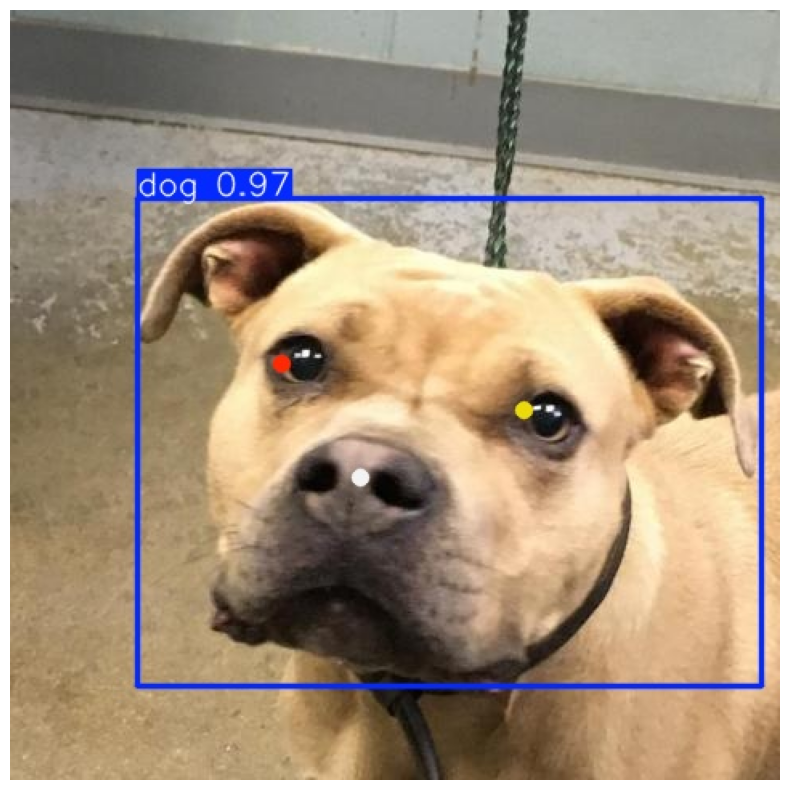

🎯 完美測試完成！


In [ ]:
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from ultralytics import YOLO

# ==========================================
# 1. 載入最佳模型
# ==========================================
model_path = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'
model = YOLO(model_path)

# ==========================================
# 2. 進行圖片預測
# ==========================================
# 確保圖片有成功下載再進行預測
local_img_path = '/content/0a26b9a7-acef-4bd4-b50e-0c532ce83dc2.png'
if os.path.exists(local_img_path):
    print("🚀 模型開始辨識本地圖片...")
    results = model.predict(source=local_img_path, save=True, conf=0.5)

    # ==========================================
    # 3. 自動抓取並顯示結果
    # ==========================================
    print("🖼️ 準備顯示預測結果...")
    latest_predict_dir = max(glob.glob('/content/runs/pose/predict*'), key=os.path.getmtime)
    result_files = glob.glob(f'{latest_predict_dir}/*.jpg')

    if result_files:
        img = mpimg.imread(result_files[0])
        plt.figure(figsize=(10, 10))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
        print("🎯 完美測試完成！")
    else:
        print("❌ 找不到預測結果的圖片。")

**先裁切臉部，再透過眼鼻座標計算出仿射矩陣，將臉部轉正**

⏳ 正在載入模型與圖片...
✅ 成功抓取特徵點！開始進行對齊...


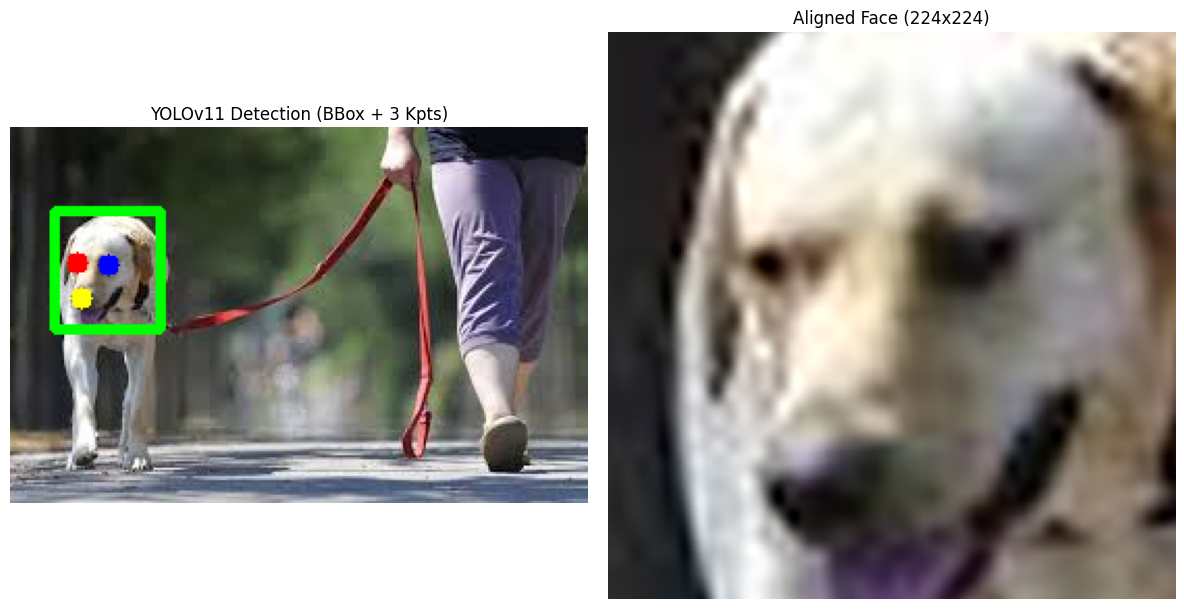

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ==========================================
# 1. 對齊函數 (使用仿射矩陣)
# ==========================================
def align_dog_face(image, keypoints, target_size=(224, 224), eye_distance_ratio=0.35, eye_height_ratio=0.4):
    kpts = np.array(keypoints, dtype=np.float32)
    left_eye, right_eye, nose = kpts[0], kpts[1], kpts[2]

    # 計算雙眼中心點和角度
    eye_center = (left_eye + right_eye) / 2.0
    dY = right_eye[1] - left_eye[1]
    dX = right_eye[0] - left_eye[0]
    angle = np.degrees(np.arctan2(dY, dX))

    # 計算縮放比例
    current_dist = np.sqrt((dX ** 2) + (dY ** 2))
    desired_dist = target_size[0] * eye_distance_ratio
    scale = desired_dist / current_dist

    # 目標影像中雙眼中心的座標
    desired_eye_center_x = target_size[0] / 2.0
    desired_eye_center_y = target_size[1] * eye_height_ratio

    # 取得仿射轉換矩陣 (包含旋轉與縮放)
    M = cv2.getRotationMatrix2D(tuple(eye_center), angle, scale)

    # 修正平移量
    M[0, 2] += (desired_eye_center_x - eye_center[0])
    M[1, 2] += (desired_eye_center_y - eye_center[1])

    # 執行仿射轉換，直接輸出 224x224 的標準圖
    aligned_face = cv2.warpAffine(image, M, target_size, flags=cv2.INTER_CUBIC)
    return aligned_face

# ==========================================
# 2. 測試對齊函數
# ==========================================
def sanity_check(model_path, image_path):
    print("⏳ 正在載入模型與圖片...")
    # 載入你訓練好的 YOLO 模型
    model = YOLO(model_path)

    # 讀取測試圖片
    img = cv2.imread(image_path)
    if img is None:
        print("❌ 找不到圖片，請檢查 image_path 路徑！")
        return
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_draw = img_rgb.copy()

    # 進行推論
    results = model(img_rgb, verbose=False)

    # 檢查有沒有抓到狗臉
    if len(results[0].boxes) == 0:
        print("❌ 模型在這張圖裡沒有找到狗臉！")
        return

    # 取出第一隻狗的資料 (邊界框和眼鼻座標)
    box = results[0].boxes.xyxy[0].cpu().numpy().astype(int)
    kpts = results[0].keypoints.xy[0].cpu().numpy() # 格式: [[x1,y1], [x2,y2], [x3,y3]]

    # 檢查關鍵點是否有效
    if np.all(kpts == 0):
        print("❌ 抓到了框，但沒有抓到關鍵點！")
        return

    print("✅ 成功抓取特徵點！開始進行對齊...")

    # ==========================================
    # 3. 繪製結果
    # ==========================================
    # --- 在原圖畫上框和點 ---
    cv2.rectangle(img_draw, (box[0], box[1]), (box[2], box[3]), (0, 255, 0), 3) # 畫綠框

    # 畫點 (左眼:紅, 右眼:藍, 鼻子:黃)
    colors = [(255, 0, 0), (0, 0, 255), (255, 255, 0)]
    for i, (x, y) in enumerate(kpts):
        cv2.circle(img_draw, (int(x), int(y)), 5, colors[i], -1)

    # --- 執行對齊 ---
    aligned_img = align_dog_face(img_rgb, kpts, target_size=(224, 224))

    # --- 顯示成果 ---
    plt.figure(figsize=(12, 6))

    # 左圖：AI 偵測結果
    plt.subplot(1, 2, 1)
    plt.imshow(img_draw)
    plt.title("YOLOv11 Detection (BBox + 3 Kpts)")
    plt.axis('off')

    # 右圖：對齊後的標準照
    plt.subplot(1, 2, 2)
    plt.imshow(aligned_img)
    plt.title("Aligned Face (224x224)")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 3. 點火執行區 (請修改這裡的路徑)
# ==========================================
# 換成你雲端硬碟裡 best.pt 的實際路徑
MY_MODEL_PATH = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'

# 隨便找一張測試圖片上傳到 Colab，換成該圖片的路徑
TEST_IMAGE_PATH = '/content/images_1.jpg'

sanity_check(MY_MODEL_PATH, TEST_IMAGE_PATH)

**先將整張照片旋轉後再進行第二次臉部裁切**

⏳ 載入模型與圖片中 (雙重偵測終極版)...


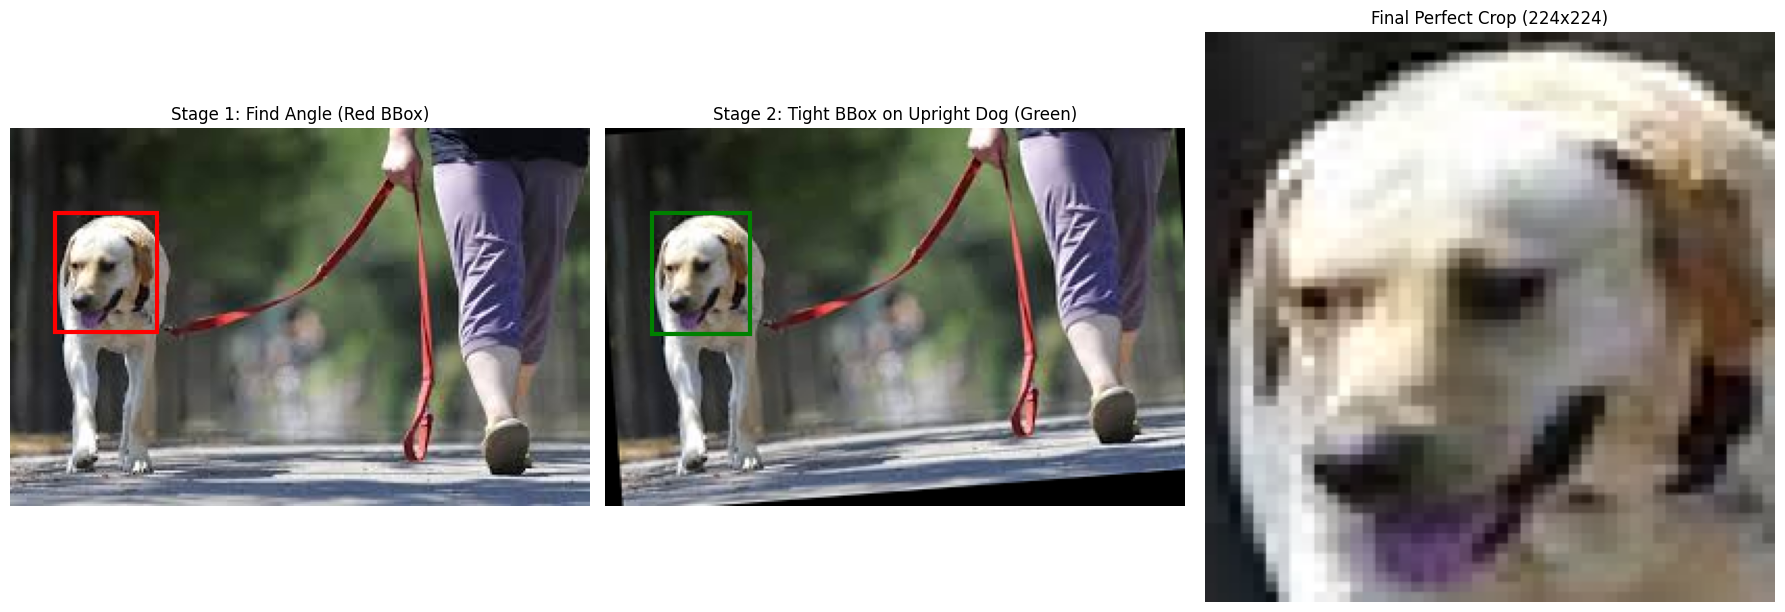

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

def two_stage_detect_and_crop(model_path, image_path, target_size=(224, 224)):
    print("⏳ 載入模型與圖片中 (雙重偵測終極版)...")
    model = YOLO(model_path)

    img = cv2.imread(image_path)
    if img is None: return print("❌ 找不到圖片！")
    h_orig, w_orig = img.shape[:2]

    # ==========================================
    # 1. 第一次偵測 (找眼鼻算角度)
    # ==========================================
    results1 = model(img, verbose=False)
    if len(results1[0].boxes) == 0: return print("❌ 第一次偵測沒抓到狗臉！")

    box1 = results1[0].boxes.xyxy[0].cpu().numpy().astype(int)
    kpts1 = results1[0].keypoints.xy[0].cpu().numpy()

    left_eye, right_eye = kpts1[0], kpts1[1]
    dX = right_eye[0] - left_eye[0]
    dY = right_eye[1] - left_eye[1]
    angle = np.degrees(np.arctan2(dY, dX))

    # 以第一次偵測到的狗臉為中心，旋轉整張大照片
    box_center_x = float((box1[0] + box1[2]) / 2.0)
    box_center_y = float((box1[1] + box1[3]) / 2.0)
    M = cv2.getRotationMatrix2D((box_center_x, box_center_y), angle, 1.0)
    rotated_full_img = cv2.warpAffine(img, M, (w_orig, h_orig), flags=cv2.INTER_CUBIC)

    # ==========================================
    # 2. 第二次偵測 (在轉正的圖上找出臉部邊界框)
    # ==========================================
    results2 = model(rotated_full_img, verbose=False)

    # 防呆機制：如果轉正後反而抓不到，就退回使用第一次的中心點切大框
    if len(results2[0].boxes) == 0:
        return print("❌ 第二次偵測失敗！狗狗轉正後模型反而認不出來了。")

    # 取得「轉正後」最緊湊的全新 BBox
    box2 = results2[0].boxes.xyxy[0].cpu().numpy().astype(int)

    # --- 直接依照第二次的完美框進行裁切 ---
    x1, y1 = max(0, box2[0]), max(0, box2[1])
    x2, y2 = min(w_orig, box2[2]), min(h_orig, box2[3])

    final_crop = rotated_full_img[y1:y2, x1:x2]
    if final_crop.size == 0: return print("❌ 裁切失敗")

    # 最終縮放
    final_img = cv2.resize(final_crop, target_size, interpolation=cv2.INTER_AREA)

    # ==========================================
    # 3. 顯示結果 
    # ==========================================
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    rotated_full_img_rgb = cv2.cvtColor(rotated_full_img, cv2.COLOR_BGR2RGB)
    final_img_rgb = cv2.cvtColor(final_img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(18, 6))

    # 【左圖】原始照片 + 第一次 YOLO 框
    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    rect1 = plt.Rectangle((box1[0], box1[1]), box1[2]-box1[0], box1[3]-box1[1], fill=False, color='red', linewidth=3)
    plt.gca().add_patch(rect1)
    plt.title("Stage 1: Find Angle (Red BBox)")
    plt.axis('off')

    # 【中圖】旋轉後的大照片 + 第二次 YOLO 完美框
    plt.subplot(1, 3, 2)
    plt.imshow(rotated_full_img_rgb)
    rect2 = plt.Rectangle((box2[0], box2[1]), box2[2]-box2[0], box2[3]-box2[1], fill=False, color='green', linewidth=3)
    plt.gca().add_patch(rect2)
    plt.title("Stage 2: Tight BBox on Upright Dog (Green)")
    plt.axis('off')

    # 【右圖】最終裁切結果
    plt.subplot(1, 3, 3)
    plt.imshow(final_img_rgb)
    plt.title(f"Final Perfect Crop ({target_size[0]}x{target_size[1]})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 4. 執行區
# ==========================================
MY_MODEL_PATH = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'
TEST_IMAGE_PATH = '/content/images.jpg'

two_stage_detect_and_crop(MY_MODEL_PATH, TEST_IMAGE_PATH)

⏳ 載入模型與圖片中...


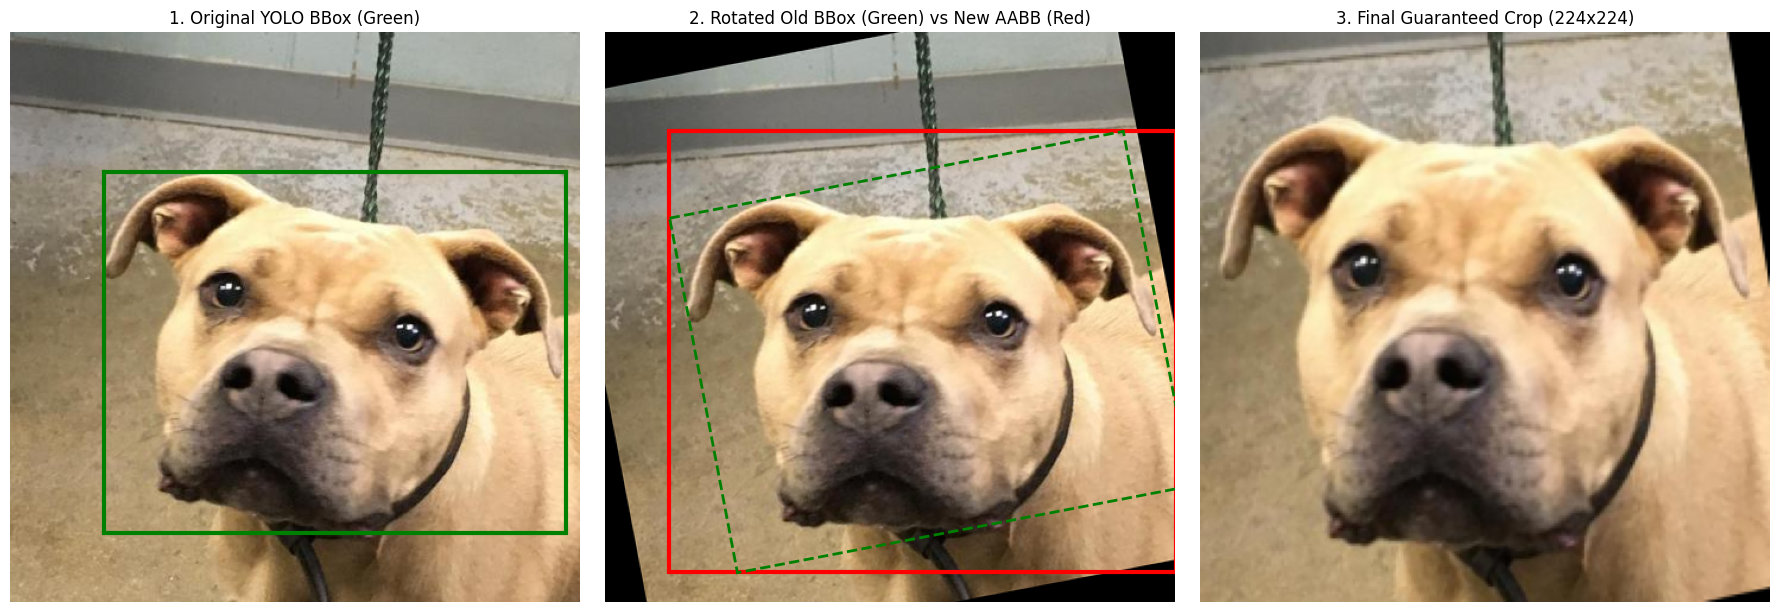

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

def rotate_whole_image_and_crop(model_path, image_path, target_size=(224, 224)):
    print("⏳ 載入模型與圖片中...")
    model = YOLO(model_path)

    # 這裡必須是 BGR，不要轉色！
    img = cv2.imread(image_path)
    if img is None: return print("❌ 找不到圖片！")

    h_orig, w_orig = img.shape[:2]

    # ==========================================
    # 1. 偵測狗臉
    # ==========================================
    results = model(img, verbose=False)
    if len(results[0].boxes) == 0: return print("❌ 沒抓到狗臉！")

    box = results[0].boxes.xyxy[0].cpu().numpy().astype(int)
    kpts = results[0].keypoints.xy[0].cpu().numpy()
    # ==========================================
    # 2. 計算角度與整體旋轉
    # ==========================================
    left_eye, right_eye = kpts[0], kpts[1]
    dX = right_eye[0] - left_eye[0]
    dY = right_eye[1] - left_eye[1]
    angle = np.degrees(np.arctan2(dY, dX))

    # 強制轉成 Python 原生的 float 數字
    box_center_x = float((box[0] + box[2]) / 2.0)
    box_center_y = float((box[1] + box[3]) / 2.0)

    # 取得整張大圖的旋轉矩陣
    M = cv2.getRotationMatrix2D((box_center_x, box_center_y), angle, 1.0)

    # 旋轉整張大照片！
    rotated_full_img = cv2.warpAffine(img, M, (w_orig, h_orig), flags=cv2.INTER_CUBIC)
    # ==========================================
    # 3. 找出原本的邊界框旋轉後的四個角落
    # ==========================================
    corners = np.array([
        [box[0], box[1]],
        [box[2], box[1]],
        [box[2], box[3]],
        [box[0], box[3]]
    ], dtype=np.float32)

    corners = np.array([corners])
    rotated_corners = cv2.transform(corners, M)[0]
    # ==========================================
    # 4. 抓最外圍點，切出最終對齊圖
    # ==========================================
    new_x1 = int(np.min(rotated_corners[:, 0]))
    new_y1 = int(np.min(rotated_corners[:, 1]))
    new_x2 = int(np.max(rotated_corners[:, 0]))
    new_y2 = int(np.max(rotated_corners[:, 1]))

    new_x1, new_y1 = max(0, new_x1), max(0, new_y1)
    new_x2, new_y2 = min(w_orig, new_x2), min(h_orig, new_y2)

    final_crop = rotated_full_img[new_y1:new_y2, new_x1:new_x2]

    if final_crop.size == 0: return print("❌ 裁切失敗")
    final_img = cv2.resize(final_crop, target_size, interpolation=cv2.INTER_AREA)
    # ==========================================
    # 5. 顯示最終成果
    # ==========================================
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # 原圖也要轉色拿來畫
    rotated_full_img_rgb = cv2.cvtColor(rotated_full_img, cv2.COLOR_BGR2RGB)
    final_img_rgb = cv2.cvtColor(final_img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(18, 6)) # 把畫布加寬塞下三張圖

    # 【左圖】原始照片 + 原始綠框
    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    rect_orig = plt.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], fill=False, color='green', linewidth=3)
    plt.gca().add_patch(rect_orig)
    plt.title("1. Original YOLO BBox (Green)")
    plt.axis('off')

    # 【中圖】旋轉大照片 + 傾斜綠色菱形 + 全新紅色大框
    plt.subplot(1, 3, 2)
    plt.imshow(rotated_full_img_rgb)
    # 畫出包覆用的紅色大框
    rect_new = plt.Rectangle((new_x1, new_y1), new_x2-new_x1, new_y2-new_y1, fill=False, color='red', linewidth=3)
    plt.gca().add_patch(rect_new)
    # 畫出原本綠框跟著旋轉後的「菱形輪廓」(綠色虛線)
    polygon = plt.Polygon(rotated_corners, fill=False, edgecolor='green', linewidth=2, linestyle='--')
    plt.gca().add_patch(polygon)
    plt.title("2. Rotated Old BBox (Green) vs New AABB (Red)")
    plt.axis('off')

    # 【右圖】最終裁切結果
    plt.subplot(1, 3, 3)
    plt.imshow(final_img_rgb)
    plt.title(f"3. Final Guaranteed Crop ({target_size[0]}x{target_size[1]})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 🚀 執行區
# ==========================================
MY_MODEL_PATH = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'
TEST_IMAGE_PATH = '/content/0a26b9a7-acef-4bd4-b50e-0c532ce83dc2.png'

rotate_whole_image_and_crop(MY_MODEL_PATH, TEST_IMAGE_PATH)

**展示有些圖片旋轉後會帶有大量黑邊，可能會影響模型判斷**

⏳ 正在載入模型與圖片...
✅ 成功抓取特徵點！開始進行對齊...


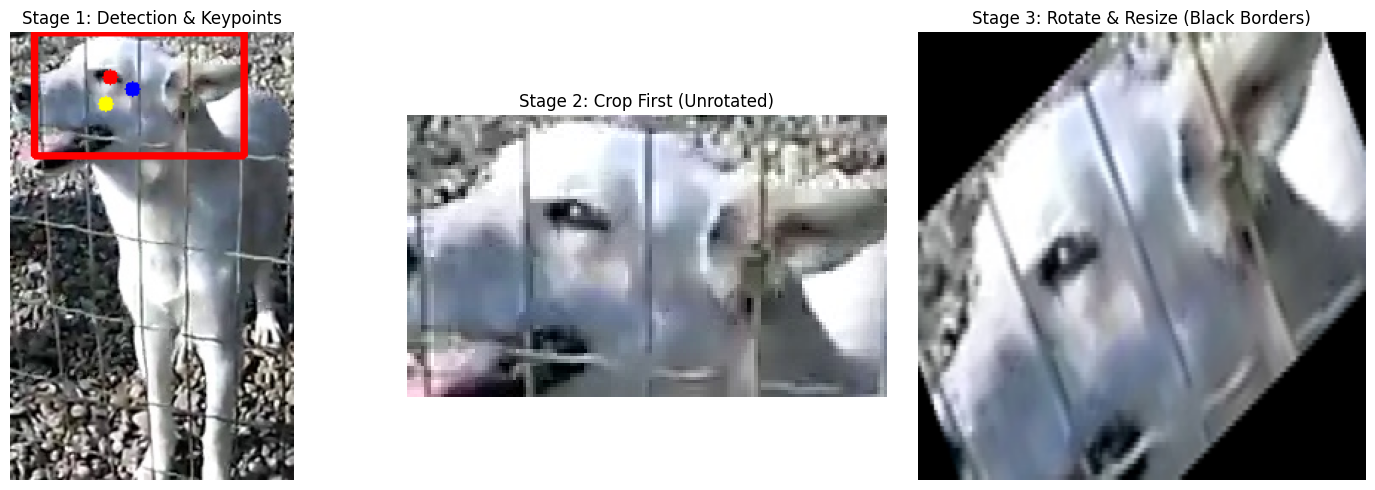

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ==========================================
# 1. 核心對齊函數 (局部邊界框旋轉法 - 展示黑邊用)
# ==========================================
def align_dog_face_full_head(image, box_new, keypoints, target_size=(224, 224)):
    """
    box_new: 你算出的紅框 [x1, y1, x2, y2]
    keypoints: YOLO 抓到的點
    """
    x1, y1, x2, y2 = box_new
    # 【階段二】：先進行局部裁切
    face_crop = image[y1:y2, x1:x2]

    if face_crop.size == 0:
        return np.zeros((target_size[1], target_size[0], 3), dtype=np.uint8), face_crop

    left_eye, right_eye = keypoints[0], keypoints[1]
    dY = right_eye[1] - left_eye[1]
    dX = right_eye[0] - left_eye[0]
    angle = np.degrees(np.arctan2(dY, dX))

    (h, w) = face_crop.shape[:2]
    center = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)

    # 【階段三】：在狹窄的 BBox 內旋轉，並填補黑色 (BORDER_CONSTANT)
    rotated_face = cv2.warpAffine(face_crop, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_CONSTANT, borderValue=(0,0,0))
    final_img = cv2.resize(rotated_face, target_size, interpolation=cv2.INTER_AREA)

    # 回傳最終圖與階段二的裁切圖，以便畫圖
    return final_img, face_crop

# ==========================================
# 2. 驗收主程式
# ==========================================
def sanity_check(model_path, image_path):
    print("⏳ 正在載入模型與圖片...")
    model = YOLO(model_path)

    img = cv2.imread(image_path)
    if img is None:
        print("❌ 找不到圖片，請檢查 image_path 路徑！")
        return

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_draw = img_rgb.copy()

    # 餵給模型的必須是原始的 BGR 圖片 (img)
    results = model(img, verbose=False)

    if len(results[0].boxes) == 0:
        print("❌ 模型在這張圖裡沒有找到狗臉！")
        return

    box = results[0].boxes.xyxy[0].cpu().numpy().astype(int)
    kpts = results[0].keypoints.xy[0].cpu().numpy()

    if np.all(kpts == 0):
        print("❌ 抓到了框，但沒有抓到關鍵點！")
        return

    print("✅ 成功抓取特徵點！開始進行對齊...")

    # 【畫階段一的圖】
    cv2.rectangle(img_draw, (box[0], box[1]), (box[2], box[3]), (255, 0, 0), 3) # 紅框
    colors = [(255, 0, 0), (0, 0, 255), (255, 255, 0)]
    for i, (x, y) in enumerate(kpts):
        cv2.circle(img_draw, (int(x), int(y)), 5, colors[i], -1)

    # 呼叫對齊函數，取得最終圖 (aligned_img) 與中間裁切圖 (raw_crop)
    aligned_img, raw_crop = align_dog_face_full_head(img_rgb, box, kpts, target_size=(224, 224))

    # ==========================================
    # 📊 畫圖展示成果 (1x3 三階段)
    # ==========================================
    plt.figure(figsize=(15, 5))

    # 圖 1：原圖 + BBox 與特徵點
    plt.subplot(1, 3, 1)
    plt.imshow(img_draw)
    plt.title("Stage 1: Detection & Keypoints")
    plt.axis('off')

    # 圖 2：先裁切出來的原始狗臉 (歪的)
    plt.subplot(1, 3, 2)
    if raw_crop.size > 0:
        plt.imshow(raw_crop)
        plt.title("Stage 2: Crop First (Unrotated)")
    else:
        plt.text(0.5, 0.5, '❌ Crop Failed', ha='center', va='center', color='red')
    plt.axis('off')

    # 圖 3：在 BBox 內旋轉的結果 (會有黑邊與裁切)
    plt.subplot(1, 3, 3)
    plt.imshow(aligned_img)
    plt.title("Stage 3: Rotate & Resize (Black Borders)")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 3. 點火執行區
# ==========================================
MY_MODEL_PATH = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'
TEST_IMAGE_PATH = '/content/2_9.jpg'

sanity_check(MY_MODEL_PATH, TEST_IMAGE_PATH)

**為解決黑邊，透過色彩填補補齊周圍黑色區域**

⏳ 載入模型與圖片中 (雙重偵測終極版)...


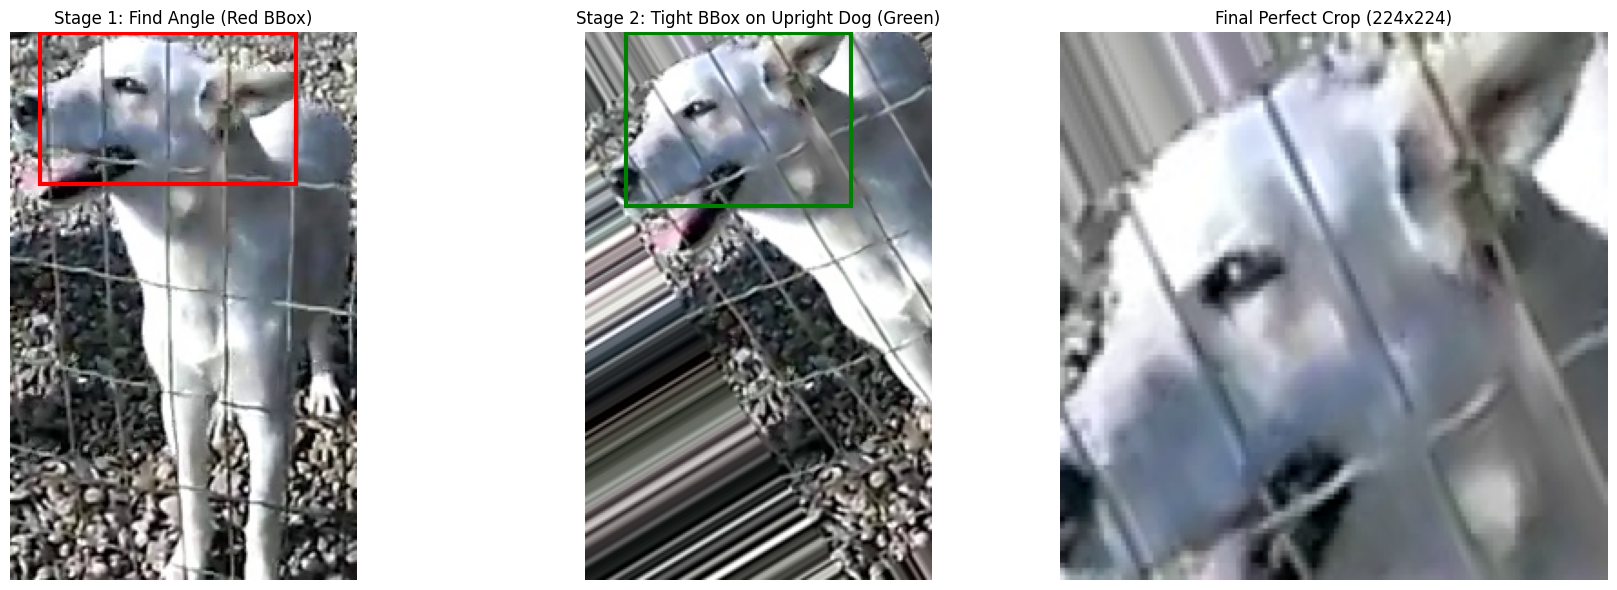

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

def two_stage_detect_and_crop(model_path, image_path, target_size=(224, 224)):
    print("⏳ 載入模型與圖片中 (雙重偵測終極版)...")
    model = YOLO(model_path)

    img = cv2.imread(image_path)
    if img is None: return print("❌ 找不到圖片！")
    h_orig, w_orig = img.shape[:2]

    # ==========================================
    # 1. 第一次偵測 (找眼睛算角度)
    # ==========================================
    results1 = model(img, verbose=False)
    if len(results1[0].boxes) == 0: return print("❌ 第一次偵測沒抓到狗臉！")

    box1 = results1[0].boxes.xyxy[0].cpu().numpy().astype(int)
    kpts1 = results1[0].keypoints.xy[0].cpu().numpy()

    left_eye, right_eye = kpts1[0], kpts1[1]
    dX = right_eye[0] - left_eye[0]
    dY = right_eye[1] - left_eye[1]
    angle = np.degrees(np.arctan2(dY, dX))

    # 以第一次偵測到的狗臉為中心，旋轉整張大照片
    box_center_x = float((box1[0] + box1[2]) / 2.0)
    box_center_y = float((box1[1] + box1[3]) / 2.0)
    M = cv2.getRotationMatrix2D((box_center_x, box_center_y), angle, 1.0)

    # 加入 borderMode=cv2.BORDER_REPLICATE 進行邊緣色彩延續
    rotated_full_img = cv2.warpAffine(
        img,
        M,
        (w_orig, h_orig),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE
    )
    # ==========================================
    # 2. 第二次偵測 (在轉正的圖上找出臉部邊界框)
    # ==========================================
    results2 = model(rotated_full_img, verbose=False)

    # 防呆機制：如果轉正後反而抓不到，就退回使用第一次的中心點切大框
    if len(results2[0].boxes) == 0:
        return print("❌ 第二次偵測失敗！狗狗轉正後模型反而認不出來了。")

    # 取得「轉正後」最緊湊的全新 BBox
    box2 = results2[0].boxes.xyxy[0].cpu().numpy().astype(int)

    # --- 直接依照第二次的完美框進行裁切 ---
    x1, y1 = max(0, box2[0]), max(0, box2[1])
    x2, y2 = min(w_orig, box2[2]), min(h_orig, box2[3])

    final_crop = rotated_full_img[y1:y2, x1:x2]
    if final_crop.size == 0: return print("❌ 裁切失敗")

    # 最終縮放
    final_img = cv2.resize(final_crop, target_size, interpolation=cv2.INTER_AREA)

    # ==========================================
    # 3. 顯示結果 
    # ==========================================
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    rotated_full_img_rgb = cv2.cvtColor(rotated_full_img, cv2.COLOR_BGR2RGB)
    final_img_rgb = cv2.cvtColor(final_img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(18, 6))

    # 【左圖】原始照片 + 第一次 YOLO 框
    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    rect1 = plt.Rectangle((box1[0], box1[1]), box1[2]-box1[0], box1[3]-box1[1], fill=False, color='red', linewidth=3)
    plt.gca().add_patch(rect1)
    plt.title("Stage 1: Find Angle (Red BBox)")
    plt.axis('off')

    # 【中圖】旋轉後的大照片 + 第二次 YOLO 完美框
    plt.subplot(1, 3, 2)
    plt.imshow(rotated_full_img_rgb)
    rect2 = plt.Rectangle((box2[0], box2[1]), box2[2]-box2[0], box2[3]-box2[1], fill=False, color='green', linewidth=3)
    plt.gca().add_patch(rect2)
    plt.title("Stage 2: Tight BBox on Upright Dog (Green)")
    plt.axis('off')

    # 【右圖】最終裁切結果
    plt.subplot(1, 3, 3)
    plt.imshow(final_img_rgb)
    plt.title(f"Final Perfect Crop ({target_size[0]}x{target_size[1]})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 4. 執行區
# ==========================================
MY_MODEL_PATH = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'
TEST_IMAGE_PATH = '/content/2_9.jpg'

two_stage_detect_and_crop(MY_MODEL_PATH, TEST_IMAGE_PATH)

In [ ]:
import os
import cv2
import numpy as np
from ultralytics import YOLO
from tqdm import tqdm #用來展示進度條

# ==========================================
# 1. 雙階段狗臉對齊核心引擎
# ==========================================
def get_two_stage_aligned_face(img, face_model, target_size=(224, 224)):
    """
    執行雙重偵測：找角度 -> 轉正全圖 -> 抓完美臉框 -> 縮放
    """
    h_orig, w_orig = img.shape[:2]

    # 第一次偵測
    results1 = face_model(img, verbose=False)
    if len(results1[0].boxes) == 0:
        return None # 沒抓到狗臉

    box1 = results1[0].boxes.xyxy[0].cpu().numpy().astype(int)

    # 兼容不同 YOLO 版本的關鍵點提取
    try:
        kpts = results1[0].keypoints.xy[0].cpu().numpy()
    except:
        kpts = results1[0].keypoints[0].cpu().numpy()

    if np.all(kpts == 0):
        return None

    # 計算旋轉角度
    left_eye, right_eye = kpts[0], kpts[1]
    dX = right_eye[0] - left_eye[0]
    dY = right_eye[1] - left_eye[1]
    angle = np.degrees(np.arctan2(dY, dX))

    # 以第一次偵測的狗臉為中心，旋轉整張原圖
    box_center_x = float((box1[0] + box1[2]) / 2.0)
    box_center_y = float((box1[1] + box1[3]) / 2.0)
    M = cv2.getRotationMatrix2D((box_center_x, box_center_y), angle, 1.0)
    rotated_full_img = cv2.warpAffine(img, M, (w_orig, h_orig), flags=cv2.INTER_CUBIC)

    # 第二次偵測
    results2 = face_model(rotated_full_img, verbose=False)

    # 如果轉正後反而抓不到，代表特徵變形，放棄這張圖以確保資料集純淨
    if len(results2[0].boxes) == 0:
        return None

    # 取得「轉正後」最緊湊的全新 BBox 並裁切
    box2 = results2[0].boxes.xyxy[0].cpu().numpy().astype(int)
    x1, y1 = max(0, box2[0]), max(0, box2[1])
    x2, y2 = min(w_orig, box2[2]), min(h_orig, box2[3])

    face_crop = rotated_full_img[y1:y2, x1:x2]
    if face_crop.size == 0:
        return None

    # 最終縮放成標準尺寸
    final_img = cv2.resize(face_crop, target_size, interpolation=cv2.INTER_AREA)
    return final_img


# ==========================================
# 2. 統整流水線主程式
# ==========================================
def process_ultimate_dogs_dataset(animal_model_path, face_model_path, input_dir, output_dir, target_size=(224, 224)):
    print("⏳ 載入雙模型中 (Animal & Face)...")
    animal_model = YOLO(animal_model_path)
    face_model = YOLO(face_model_path)

    # 建立輸出目錄
    dog_full_dir = os.path.join(output_dir, "dog_full")
    dog_face_aligned_dir = os.path.join(output_dir, "dog_face_aligned")
    os.makedirs(dog_full_dir, exist_ok=True)
    os.makedirs(dog_face_aligned_dir, exist_ok=True)

    valid_exts = {'.jpg', '.jpeg', '.png', '.bmp'}
    image_files = [f for f in os.listdir(input_dir) if os.path.splitext(f)[1].lower() in valid_exts]
    print(f"🚀 開始批次處理 {len(image_files)} 張圖片...")

    success_count = 0

    for filename in tqdm(image_files, desc="處理進度"):
        img_path = os.path.join(input_dir, filename)
        img = cv2.imread(img_path)
        if img is None: continue

        # ==========================================
        # 一、動物全身偵測與裁切
        # ==========================================
        results_animal = animal_model(img, verbose=False)
        if len(results_animal[0].boxes) > 0:
            dog_box_full = None

            # 💡 專業防呆：COCO 資料集裡「狗」的 Class ID 是 16
            # 遍歷抓到的所有物件，只挑選狗，避免把旁邊的主人切下來
            for box in results_animal[0].boxes:
                if int(box.cls[0]) == 16:
                    dog_box_full = box.xyxy[0].cpu().numpy().astype(int)
                    break

            # 如果沒找到 16 號 (狗)，就退而求其次抓第一個物件
            if dog_box_full is None:
                dog_box_full = results_animal[0].boxes.xyxy[0].cpu().numpy().astype(int)

            # 裁切並儲存全身照
            dog_full_crop = img[max(0, dog_box_full[1]):dog_box_full[3], max(0, dog_box_full[0]):dog_box_full[2]]
            if dog_full_crop.size > 0:
                full_dog_filename = f"{os.path.splitext(filename)[0]}_full.jpg"
                cv2.imwrite(os.path.join(dog_full_dir, full_dog_filename), dog_full_crop)


        # ==========================================
        # 二、雙階段狗臉對齊與裁切
        # ==========================================
        aligned_dog_face = get_two_stage_aligned_face(img, face_model, target_size=target_size)

        if aligned_dog_face is not None:
            face_dog_filename = f"{os.path.splitext(filename)[0]}_face.jpg"
            cv2.imwrite(os.path.join(dog_face_aligned_dir, face_dog_filename), aligned_dog_face)
            success_count += 1

    print("\n=========================================")
    print(f"🎉 終極清洗大功告成！")
    print(f"✅ 成功產出完美狗臉: {success_count} / {len(image_files)} 張")
    print(f"📁 全身圖已存入: {dog_full_dir}")
    print(f"📁 雙重對齊臉已存入: {dog_face_aligned_dir}")
    print("=========================================")

# ==========================================
# 3.  點火執行區 (請修改這 4 個路徑)
# ==========================================
ANIMAL_MODEL_PATH = '/content/yolo11s.pt'
FACE_MODEL_PATH = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'
INPUT_DIR = '/content/drive/MyDrive/Raw_Dogs'
OUTPUT_DIR = '/content/Processed_Dogs_Dataset'

process_ultimate_dogs_dataset(ANIMAL_MODEL_PATH, FACE_MODEL_PATH, INPUT_DIR, OUTPUT_DIR)

⏳ 載入雙模型中 (Animal & Face)...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Raw_Dogs'

**先旋轉後裁切，最後拉伸成指定長寬**

!但拉伸可能導致臉部變形，降低匹配準確度!

⏳ 載入雙模型中 (全身模型 + 臉部對齊模型)...
✅ 圖片讀取成功，開始處理...


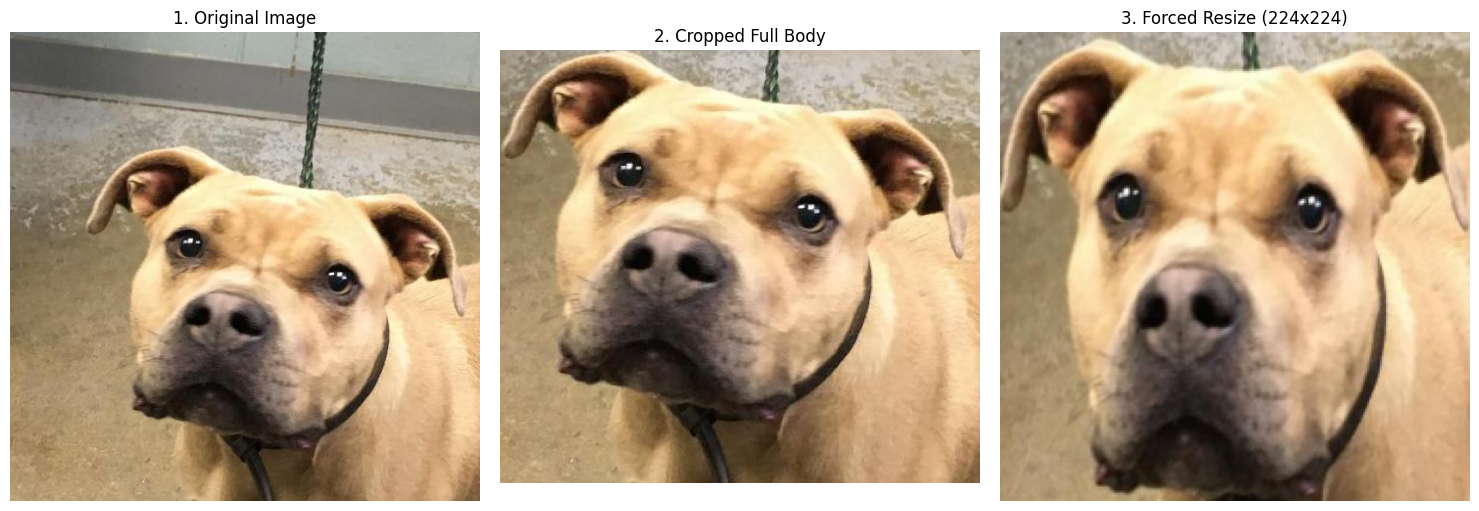

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

def test_single_image_pipeline(animal_model_path, face_model_path, image_path, target_face_size=(224, 224)):
    print("⏳ 載入雙模型中 (全身模型 + 臉部對齊模型)...")
    animal_model = YOLO(animal_model_path)
    face_model = YOLO(face_model_path)

    # 讀取圖片 (保持 BGR 通道)
    img = cv2.imread(image_path)
    if img is None:
        return print("❌ 找不到圖片，請檢查路徑！")
    h_orig, w_orig = img.shape[:2]

    print("✅ 圖片讀取成功，開始處理...")
    dog_full_crop = None
    aligned_dog_face = None

    # ==========================================
    # 1. 偵測並裁切「狗全身」 (使用 YOLO11s)
    # ==========================================
    results_animal = animal_model(img, verbose=False)
    if len(results_animal[0].boxes) > 0:
        for box in results_animal[0].boxes:
            if int(box.cls[0]) == 16:  # COCO 資料集 16 號是狗
                b = box.xyxy[0].cpu().numpy().astype(int)
                dog_full_crop = img[max(0, b[1]):b[3], max(0, b[0]):b[2]]
                break

        # 防呆：如果沒抓到 16 號標籤，就抓畫面中第一個最大物件
        if dog_full_crop is None:
            b = results_animal[0].boxes.xyxy[0].cpu().numpy().astype(int)
            dog_full_crop = img[max(0, b[1]):b[3], max(0, b[0]):b[2]]

    # ==========================================
    # 2. 偵測並裁切轉正狗臉
    # ==========================================
    # 階段 1：找眼睛算角度
    results_face1 = face_model(img, verbose=False)
    if len(results_face1[0].boxes) > 0:
        box1 = results_face1[0].boxes.xyxy[0].cpu().numpy().astype(int)

        try:
            kpts = results_face1[0].keypoints.xy[0].cpu().numpy()
        except:
            kpts = results_face1[0].keypoints[0].cpu().numpy()

        if not np.all(kpts == 0):
            left_eye, right_eye = kpts[0], kpts[1]
            dX = right_eye[0] - left_eye[0]
            dY = right_eye[1] - left_eye[1]
            angle = np.degrees(np.arctan2(dY, dX))

            # 旋轉全圖 (保留消除黑邊功能)
            center = (float((box1[0]+box1[2])/2.0), float((box1[1]+box1[3])/2.0))
            M = cv2.getRotationMatrix2D(center, angle, 1.0)
            rotated_img = cv2.warpAffine(img, M, (w_orig, h_orig), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

            # 階段 2：在轉正的圖上重新抓臉並裁切
            results_face2 = face_model(rotated_img, verbose=False)
            if len(results_face2[0].boxes) > 0:
                box2 = results_face2[0].boxes.xyxy[0].cpu().numpy().astype(int)
                face_crop = rotated_img[max(0, box2[1]):box2[3], max(0, box2[0]):box2[2]]

                if face_crop.size > 0:
                    # ⚠️ 關鍵退回：直接使用 cv2.resize 強制縮放，故意讓狗臉拉伸變形！
                    aligned_dog_face = cv2.resize(face_crop, target_face_size, interpolation=cv2.INTER_AREA)

    # ==========================================
    # 3. 展示成果
    # ==========================================
    plt.figure(figsize=(15, 5))

    # 圖 1：原圖
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("1. Original Image")
    plt.axis('off')

    # 圖 2：全身裁切結果
    plt.subplot(1, 3, 2)
    if dog_full_crop is not None:
        plt.imshow(cv2.cvtColor(dog_full_crop, cv2.COLOR_BGR2RGB))
        plt.title("2. Cropped Full Body")
    else:
        plt.text(0.5, 0.5, '❌ No Dog Body Found', ha='center', va='center', fontsize=15, color='red')
    plt.axis('off')

    # 圖 3：轉正狗臉裁切結果 (會變形的版本)
    plt.subplot(1, 3, 3)
    if aligned_dog_face is not None:
        plt.imshow(cv2.cvtColor(aligned_dog_face, cv2.COLOR_BGR2RGB))
        plt.title(f"3. Forced Resize ({target_face_size[0]}x{target_face_size[1]})")
    else:
        plt.text(0.5, 0.5, '❌ No Face Found', ha='center', va='center', fontsize=15, color='red')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 4. 點火執行區
# ==========================================
ANIMAL_MODEL_PATH = '/content/yolo11s.pt'
FACE_MODEL_PATH = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'
TEST_IMAGE_PATH = '/content/0a26b9a7-acef-4bd4-b50e-0c532ce83dc2.png'

test_single_image_pipeline(ANIMAL_MODEL_PATH, FACE_MODEL_PATH, TEST_IMAGE_PATH)

**先旋轉後裁切，但最後不拉伸成指定長寬，而是**

!但拉伸可能導致臉部變形，降低匹配準確度!

⏳ 載入雙模型中 (全身模型 + 臉部對齊模型)...
✅ 圖片讀取成功，開始處理...


/tmp/ipykernel_3295/2681221512.py:125: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


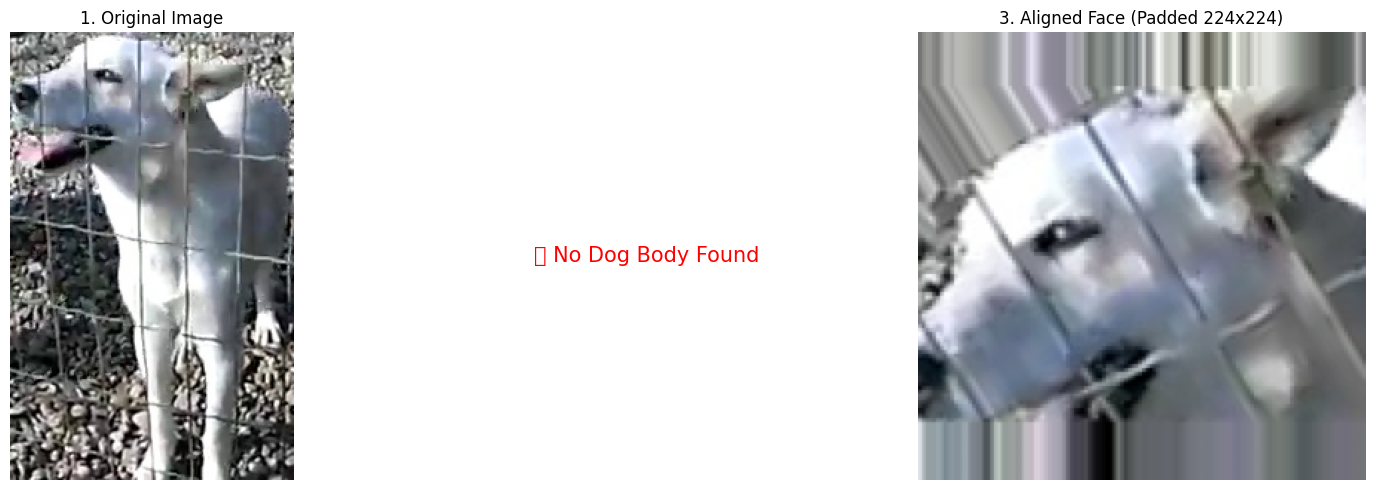

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt # 用來畫圖給我看
from ultralytics import YOLO

# ==========================================
# 防變形置中與邊緣延續函數
# ==========================================
def resize_with_pad(image, target_size=224):
    """
    等比例縮放並使用「邊緣延伸 (Edge Replicate)」補邊，
    保證特徵不變形，且不產生干擾 AI 的銳利黑邊！
    """
    h, w = image.shape[:2]
    max_side = max(h, w)

    # 計算需要補的邊界大小
    top = (max_side - h) // 2
    bottom = max_side - h - top
    left = (max_side - w) // 2
    right = max_side - w - left

    # 使用 cv2.BORDER_REPLICATE 向外延伸最外圍的像素顏色
    padded_img = cv2.copyMakeBorder(image, top, bottom, left, right, cv2.BORDER_REPLICATE)

    # 安全縮放至目標尺寸
    final_img = cv2.resize(padded_img, (target_size, target_size), interpolation=cv2.INTER_AREA)
    return final_img


def test_single_image_pipeline(animal_model_path, face_model_path, image_path, target_face_size=(224, 224)):
    print("⏳ 載入雙模型中 (全身模型 + 臉部對齊模型)...")
    animal_model = YOLO(animal_model_path)
    face_model = YOLO(face_model_path)

    # 讀取圖片 (保持 BGR 通道)
    img = cv2.imread(image_path)
    if img is None:
        return print("❌ 找不到圖片，請檢查路徑！")
    h_orig, w_orig = img.shape[:2]

    print("✅ 圖片讀取成功，開始處理...")
    dog_full_crop = None
    aligned_dog_face = None

    # ==========================================
    # 1. 偵測並裁切狗全身 (使用 YOLO11s)
    # ==========================================
    results_animal = animal_model(img, verbose=False)
    if len(results_animal[0].boxes) > 0:
        for box in results_animal[0].boxes:
            if int(box.cls[0]) == 16:  # COCO 資料集 16 號是狗
                b = box.xyxy[0].cpu().numpy().astype(int)
                dog_full_crop = img[max(0, b[1]):b[3], max(0, b[0]):b[2]]
                break

        # 如果沒抓到 16 號標籤，就抓畫面中第一個最大物件
        if dog_full_crop is None:
            b = results_animal[0].boxes.xyxy[0].cpu().numpy().astype(int)
            dog_full_crop = img[max(0, b[1]):b[3], max(0, b[0]):b[2]]

    # ==========================================
    # 2. 偵測並裁切轉正狗臉
    # ==========================================
    # 找眼睛算角度
    results_face1 = face_model(img, verbose=False)
    if len(results_face1[0].boxes) > 0:
        box1 = results_face1[0].boxes.xyxy[0].cpu().numpy().astype(int)

        try:
            kpts = results_face1[0].keypoints.xy[0].cpu().numpy()
        except:
            kpts = results_face1[0].keypoints[0].cpu().numpy()

        if not np.all(kpts == 0):
            left_eye, right_eye = kpts[0], kpts[1]
            dX = right_eye[0] - left_eye[0]
            dY = right_eye[1] - left_eye[1]
            angle = np.degrees(np.arctan2(dY, dX))

            # 旋轉全圖
            center = (float((box1[0]+box1[2])/2.0), float((box1[1]+box1[3])/2.0))
            M = cv2.getRotationMatrix2D(center, angle, 1.0)
            rotated_img = cv2.warpAffine(img, M, (w_orig, h_orig), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

            # 在轉正的圖上重新抓臉並裁切
            results_face2 = face_model(rotated_img, verbose=False)
            if len(results_face2[0].boxes) > 0:
                box2 = results_face2[0].boxes.xyxy[0].cpu().numpy().astype(int)
                face_crop = rotated_img[max(0, box2[1]):box2[3], max(0, box2[0]):box2[2]]

                if face_crop.size > 0:
                    # 呼叫自訂函數，不變形置中並補上周圍色彩
                    aligned_dog_face = resize_with_pad(face_crop, target_size=target_face_size[0])

    # ==========================================
    # 3. 成果展示
    # ==========================================
    plt.figure(figsize=(15, 5))

    # 圖 1：原圖
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("1. Original Image")
    plt.axis('off')

    # 圖 2：全身裁切結果
    plt.subplot(1, 3, 2)
    if dog_full_crop is not None:
        plt.imshow(cv2.cvtColor(dog_full_crop, cv2.COLOR_BGR2RGB))
        plt.title("2. Cropped Full Body")
    else:
        plt.text(0.5, 0.5, '❌ No Dog Body Found', ha='center', va='center', fontsize=15, color='red')
    plt.axis('off')

    # 圖 3：轉正狗臉裁切結果 (使用色彩填補)
    plt.subplot(1, 3, 3)
    if aligned_dog_face is not None:
        plt.imshow(cv2.cvtColor(aligned_dog_face, cv2.COLOR_BGR2RGB))
        plt.title(f"3. Aligned Face (Padded {target_face_size[0]}x{target_face_size[1]})")
    else:
        plt.text(0.5, 0.5, '❌ No Face Found', ha='center', va='center', fontsize=15, color='red')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 4. 執行區
# ==========================================
ANIMAL_MODEL_PATH = '/content/yolo11s.pt'
FACE_MODEL_PATH = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'
TEST_IMAGE_PATH = '/content/2_9.jpg' # 換成要測試的圖片

test_single_image_pipeline(ANIMAL_MODEL_PATH, FACE_MODEL_PATH, TEST_IMAGE_PATH)

**信心低也印，嘗試解決鐵絲網導致偵測不到下巴的問題**



⏳ 載入雙模型中 (終極整合版)...
✅ 圖片讀取成功，開始處理...


/tmp/ipykernel_3295/3765798021.py:145: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


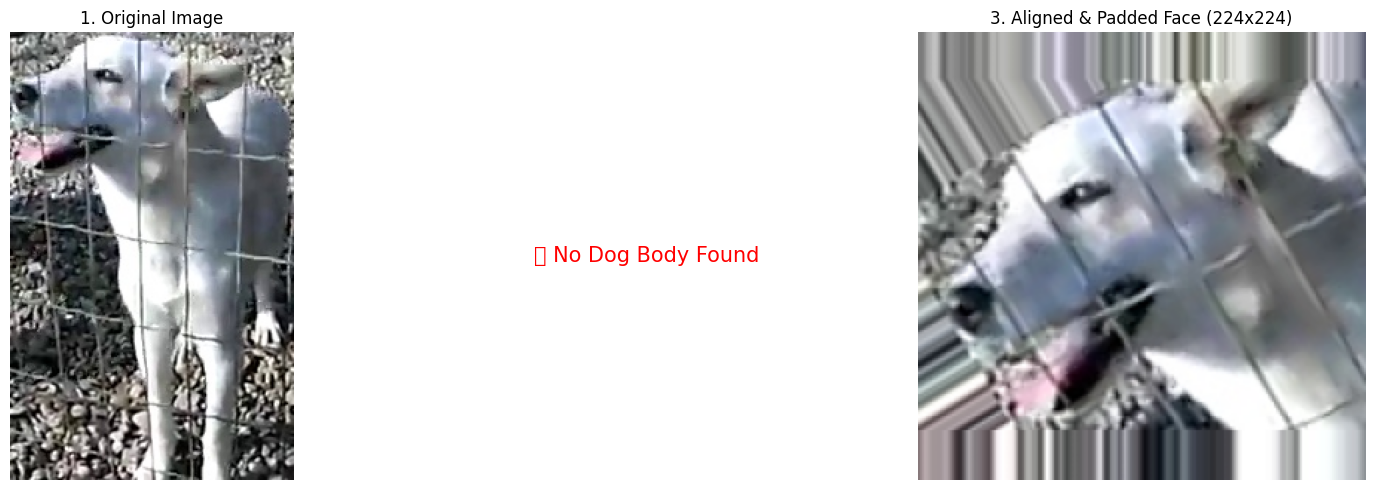

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ==========================================
# 1. 防變形置中與邊緣延續函數
# ==========================================
def resize_with_pad(image, target_size=224):
    """
    等比例縮放並使用邊緣延伸補邊，
    特徵不變形，且不產生黑邊
    """
    if image.size == 0: return np.zeros((target_size, target_size, 3), dtype=np.uint8)
    h, w = image.shape[:2]
    max_side = max(h, w)

    # 計算需要補的邊界大小
    top = (max_side - h) // 2
    bottom = max_side - h - top
    left = (max_side - w) // 2
    right = max_side - w - left

    # 使用 cv2.BORDER_REPLICATE 向外延伸最外圍的像素顏色
    padded_img = cv2.copyMakeBorder(image, top, bottom, left, right, cv2.BORDER_REPLICATE)

    # 安全縮放至目標尺寸
    final_img = cv2.resize(padded_img, (target_size, target_size), interpolation=cv2.INTER_AREA)
    return final_img

# ==========================================
# 2. 終極整合版管線主程式
# ==========================================
def test_integrated_pipeline(animal_model_path, face_model_path, image_path, target_face_size=(224, 224)):
    print("⏳ 載入雙模型中 (終極整合版)...")
    animal_model = YOLO(animal_model_path)
    face_model = YOLO(face_model_path)

    # 讀取圖片 (保持 BGR 通道)
    img = cv2.imread(image_path)
    if img is None: return print("❌ 找不到圖片，請檢查路徑！")
    h_orig, w_orig = img.shape[:2]

    print("✅ 圖片讀取成功，開始處理...")
    dog_full_crop = None
    aligned_dog_face = None

    # ==========================================
    # 一、偵測並裁切狗全身
    # ==========================================
    # 💡 整合特點 1：調降門檻 conf=0.15 應對鐵絲網等嚴重遮蔽場景
    results_animal = animal_model(img, conf=0.15, verbose=False)

    if len(results_animal[0].boxes) > 0:
        for box in results_animal[0].boxes:
            if int(box.cls[0]) == 16:  # COCO 資料集 16 號是狗
                b = box.xyxy[0].cpu().numpy().astype(int)
                dog_full_crop = img[max(0, b[1]):b[3], max(0, b[0]):b[2]]
                break

        # 如果沒抓到 16 號標籤，就抓畫面中第一個最大物件
        if dog_full_crop is None:
            b = results_animal[0].boxes.xyxy[0].cpu().numpy().astype(int)
            dog_full_crop = img[max(0, b[1]):b[3], max(0, b[0]):b[2]]

    # ==========================================
    # 二、偵測裁切並轉正狗臉
    # ==========================================
    # 找眼睛算角度
    results_face1 = face_model(img, conf=0.15, verbose=False)
    if len(results_face1[0].boxes) > 0:
        box1 = results_face1[0].boxes.xyxy[0].cpu().numpy().astype(int)

        try:
            kpts = results_face1[0].keypoints.xy[0].cpu().numpy()
        except:
            kpts = results_face1[0].keypoints[0].cpu().numpy()

        if not np.all(kpts == 0):
            left_eye, right_eye = kpts[0], kpts[1]
            dX = right_eye[0] - left_eye[0]
            dY = right_eye[1] - left_eye[1]
            angle = np.degrees(np.arctan2(dY, dX))

            # 全圖旋轉
            center = (float((box1[0]+box1[2])/2.0), float((box1[1]+box1[3])/2.0))
            M = cv2.getRotationMatrix2D(center, angle, 1.0)

            # 全圖旋轉時使用 BORDER_REPLICATE 消除黑邊
            rotated_img = cv2.warpAffine(img, M, (w_orig, h_orig), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

            # 在轉正的圖上重新抓臉
            results_face2 = face_model(rotated_img, conf=0.15, verbose=False)
            if len(results_face2[0].boxes) > 0:
                box2 = results_face2[0].boxes.xyxy[0].cpu().numpy().astype(int)

                # 動態擴張 Bounding Box (防止張嘴的下巴被裁掉)
                x1, y1, x2, y2 = box2
                box_w = x2 - x1
                box_h = y2 - y1

                # 向下(下巴)多擴張 35%，向上(耳朵)擴張 15%，左右擴張 15%
                new_y1 = max(0, int(y1 - box_h * 0.15))
                new_y2 = min(h_orig, int(y2 + box_h * 0.35))
                new_x1 = max(0, int(x1 - box_w * 0.15))
                new_x2 = min(w_orig, int(x2 + box_w * 0.15))

                face_crop = rotated_img[new_y1:new_y2, new_x1:new_x2]

                if face_crop.size > 0:
                    # 不變形置中並補上周圍色彩
                    aligned_dog_face = resize_with_pad(face_crop, target_size=target_face_size[0])

    # ==========================================
    # 三、畫圖展示成果
    # ==========================================
    plt.figure(figsize=(15, 5))

    # 圖 1：原圖
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("1. Original Image")
    plt.axis('off')

    # 圖 2：全身裁切結果
    plt.subplot(1, 3, 2)
    if dog_full_crop is not None:
        plt.imshow(cv2.cvtColor(dog_full_crop, cv2.COLOR_BGR2RGB))
        plt.title("2. Cropped Full Body")
    else:
        plt.text(0.5, 0.5, '❌ No Dog Body Found', ha='center', va='center', fontsize=15, color='red')
    plt.axis('off')

    # 圖 3：轉正狗臉裁切結果
    plt.subplot(1, 3, 3)
    if aligned_dog_face is not None:
        plt.imshow(cv2.cvtColor(aligned_dog_face, cv2.COLOR_BGR2RGB))
        plt.title(f"3. Aligned & Padded Face ({target_face_size[0]}x{target_face_size[1]})")
    else:
        plt.text(0.5, 0.5, '❌ No Face Found', ha='center', va='center', fontsize=15, color='red')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 3. 點火執行區
# ==========================================
ANIMAL_MODEL_PATH = '/content/yolo11s.pt'
FACE_MODEL_PATH = '/content/drive/MyDrive/DogFace_Backups2/epoch_30_best.pt'
TEST_IMAGE_PATH = '/content/2_9.jpg' # 放上鐵絲網狗狗測試

test_integrated_pipeline(ANIMAL_MODEL_PATH, FACE_MODEL_PATH, TEST_IMAGE_PATH)